# Exploratory Data Analysis: Customer Churn

**Project:** AI-Based Customer Churn Prediction and Retention Analytics
**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)
**Goal of this notebook:** understand which customer characteristics are associated with churn before building models.

All numbers below were produced by running this notebook on the cleaned data. Run the project from the project root first:
`python -m src.data_loader`


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
os.chdir(os.path.abspath(".."))

import pandas as pd
import matplotlib.pyplot as plt
from src import eda
from src.data_loader import load_raw_data, clean_data, quality_report

%matplotlib inline
raw = load_raw_data()
df = eda.load_data()
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,ChurnLabel
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12 months,Stayed
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48 months,Stayed
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12 months,Churned
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48 months,Stayed
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12 months,Churned


## 1. Dataset overview and data quality

In [2]:
print("Raw shape:", raw.shape)
print()
print(raw.dtypes.to_string())

Raw shape: (7043, 21)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str


`TotalCharges` is stored as text (`str`) in the raw file even though it holds numbers. This is the incorrect data type that cleaning fixes. `SeniorCitizen` is stored as 0/1 and is converted to No/Yes.

In [3]:
report = quality_report(raw, clean_data(raw))
pd.Series(report)

raw_rows                         7043.0000
raw_columns                        21.0000
duplicate_customer_ids              0.0000
missing_values_raw                  0.0000
total_charges_not_numeric          11.0000
rows_after_cleaning              7043.0000
missing_values_after_cleaning       0.0000
churned                          1869.0000
churn_rate                          0.2654
dtype: float64

**Findings from the data quality check**
- There are no duplicate customer IDs and no ordinary missing values.
- 11 rows have a blank `TotalCharges`. All 11 are customers with `tenure = 0` (brand-new customers who have not been billed yet), so `TotalCharges` was set to 0 for them instead of deleting them. All 7,043 rows are kept.
- 1,869 of 7,043 customers churned (26.54%). The classes are imbalanced: roughly 1 churner for every 2.8 customers who stayed.

In [4]:
df.describe().round(2)

,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,0.27
std,24.56,30.09,2266.79,0.44
min,0.00,18.25,0.00,0.00
25%,9.00,35.50,398.55,0.00
50%,29.00,70.35,1394.55,0.00
75%,55.00,89.85,3786.60,1.00
max,72.00,118.75,8684.80,1.00


## 2. Overall churn distribution

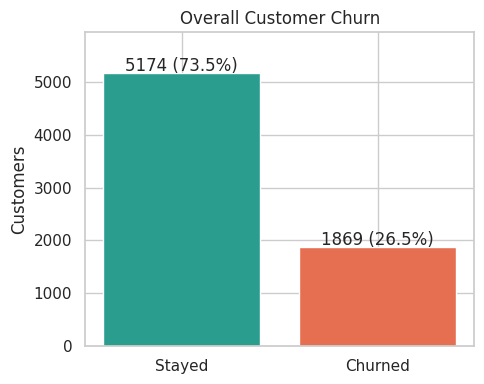

In [5]:
eda.plot_churn_distribution(df, save=True); plt.show()

**What it shows:** 5,174 customers stayed and 1,869 churned (26.5%). If a model simply predicted "stay" for everyone it would be right about 73.5% of the time while catching zero churners. This is why accuracy alone is not a good measure here and why we also use recall, precision, F1 and ROC-AUC.

## 3. Churn by contract type

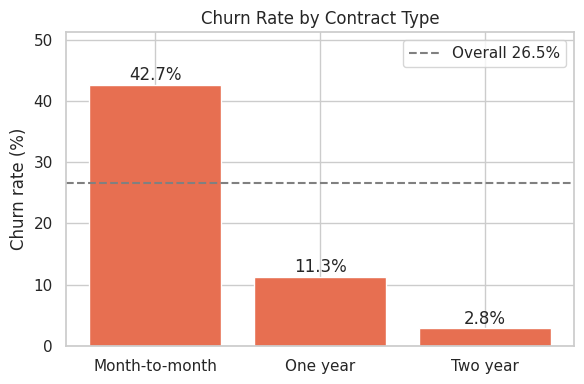

,Contract,customers,churned,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [6]:
eda.plot_contract(df, save=True); plt.show()
eda.churn_rate_by(df, "Contract")

**What it shows:** Month-to-month customers churn at 42.7%, one-year customers at 11.3%, and two-year customers at 2.8%. Month-to-month customers are 3,875 of the 7,043 customers but account for 1,655 of the 1,869 churners (about 88.6%). Customers on longer contracts are committed and leave far less often. Contract type is one of the strongest signals in the dataset.

## 4. Customer tenure and churn

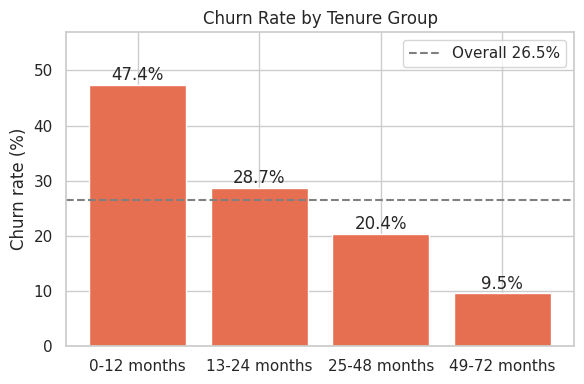

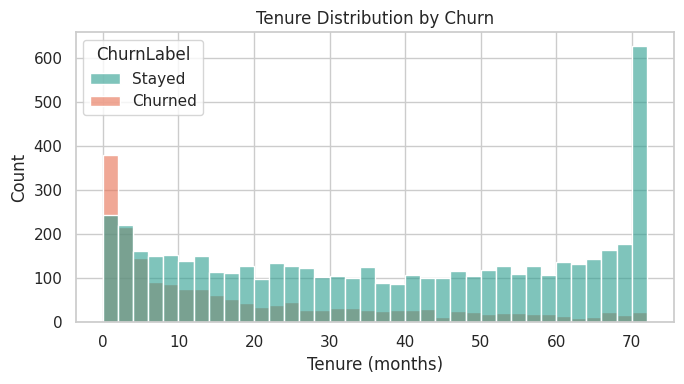

,mean,median
ChurnLabel,,
Churned,18.0,10.0
Stayed,37.6,38.0


In [7]:
eda.plot_tenure_group(df, save=True); plt.show()
eda.plot_tenure_distribution(df, save=True); plt.show()
df.groupby("ChurnLabel")["tenure"].agg(["mean", "median"]).round(1)

**What it shows:** Churn falls steadily with tenure: 47.4% in the first 12 months, 28.7% for 13-24 months, 20.4% for 25-48 months, and 9.5% beyond 48 months. Churned customers had a median tenure of 10 months, compared with 38 months for customers who stayed. The first year is the most dangerous period, so onboarding and early engagement matter.

## 5. Monthly charges and churn

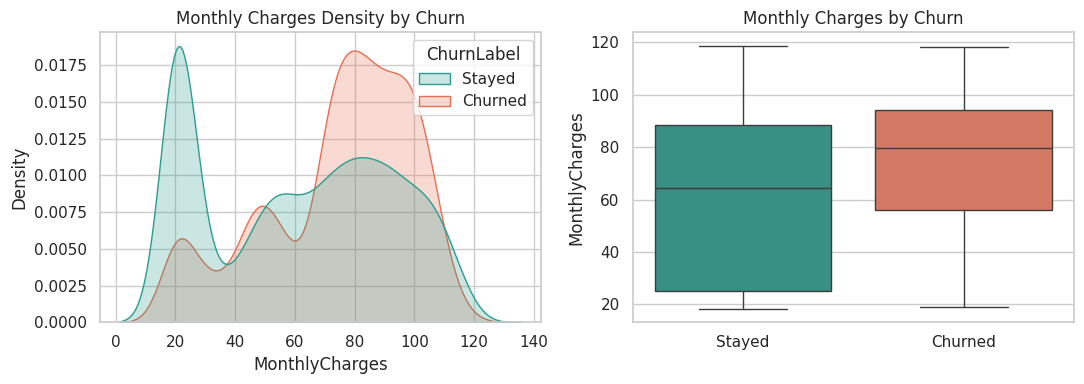

,customers,churn_rate
MonthlyCharges,,
up to 35,1735,0.109
35-70,1725,0.239
70-90,1844,0.378
above 90,1739,0.328


In [8]:
eda.plot_monthly_charges(df, save=True); plt.show()
bands = pd.cut(df["MonthlyCharges"], [0, 35, 70, 90, 200], labels=["up to 35", "35-70", "70-90", "above 90"])
df.groupby(bands, observed=True)["Churn"].agg(customers="count", churn_rate="mean").round(3)

**What it shows:** Churned customers pay more on average (mean 74.44 vs 61.27; median 79.65 vs 64.43). Customers paying 35 or less churn at 10.9%, while those paying 70-90 churn at 37.8%. The highest band (above 90) is slightly lower at 32.8%, so the relationship is not a simple straight line. The peak of low-paying stayers near 20 is almost entirely customers with no internet service (1,526 of the 1,653 customers paying 30 or less), and they churn the least (7.4%).

## 6. Payment method and churn

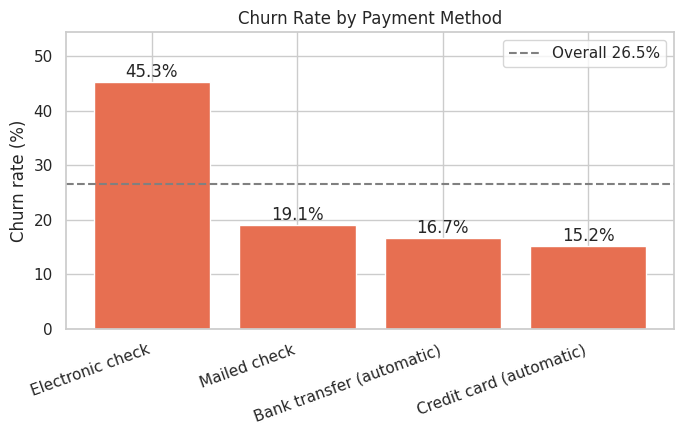

,PaymentMethod,customers,churned,churn_rate
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [9]:
eda.plot_payment(df, save=True); plt.show()
eda.churn_rate_by(df, "PaymentMethod")

**What it shows:** Electronic check customers churn at 45.3%, far above mailed check (19.1%), bank transfer (16.7%) and credit card (15.2%). The two automatic payment methods have the lowest churn. This is an association: electronic check may be a marker of other things (such as newer or month-to-month customers) rather than the cause of leaving.

## 7. Internet service and add-on services

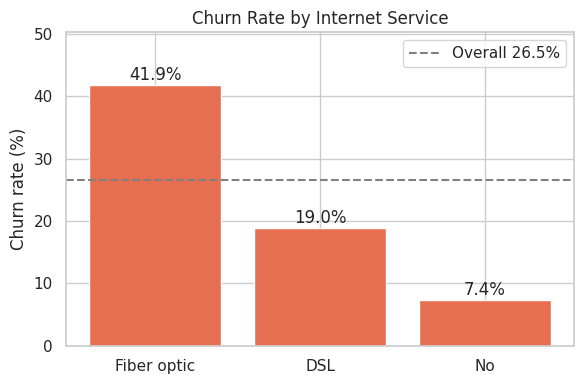

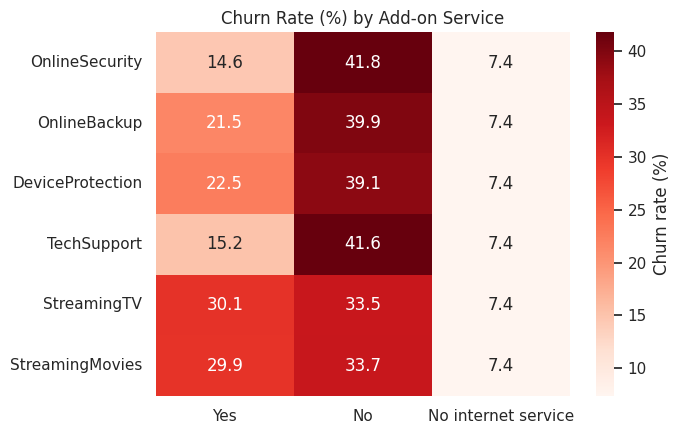

In [10]:
eda.plot_internet(df, save=True); plt.show()
eda.plot_services_heatmap(df, save=True); plt.show()

**What it shows:** Fiber optic customers churn at 41.9%, compared with 19.0% for DSL and 7.4% for customers with no internet. Among internet customers, those without Tech Support churn at 41.6% versus 15.2% with it, and those without Online Security churn at 41.8% versus 14.6% with it. Customers who use protective and support add-ons are more settled. Fiber is the most expensive plan (average monthly charge 91.50, against 58.10 for DSL), and the data does not tell us whether the higher churn is caused by price, service quality or competition.

## 8. Demographics and billing

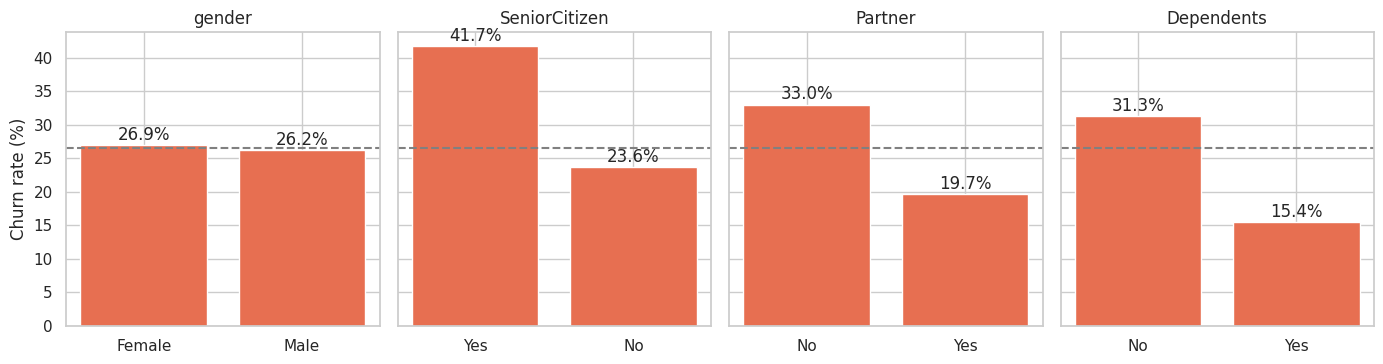

,PaperlessBilling,customers,churned,churn_rate
0,Yes,4171,1400,33.57
1,No,2872,469,16.33


In [11]:
eda.plot_demographics(df, save=True); plt.show()
eda.churn_rate_by(df, "PaperlessBilling")

**What it shows:**
- Gender makes almost no difference (female 26.9%, male 26.2%), so it carries little information.
- Senior citizens churn at 41.7% versus 23.6% for others.
- Customers without a partner churn at 33.0% (19.7% with a partner), and without dependents at 31.3% (15.5% with dependents).
- Paperless billing customers churn at 33.6% versus 16.3% for others.

## 9. Correlation of numeric features

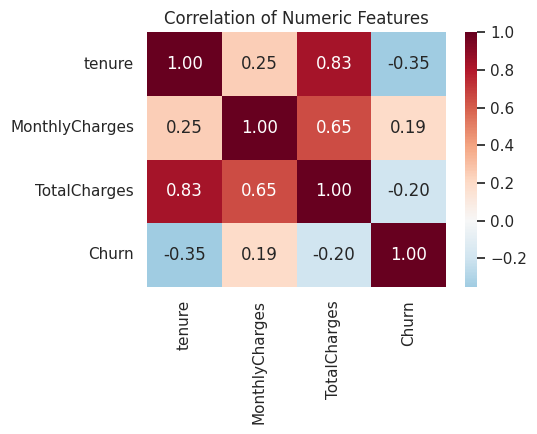

In [12]:
eda.plot_correlation(df, save=True); plt.show()

**What it shows:** Tenure has a moderate negative correlation with churn (-0.35). Monthly charges have a weak positive correlation (0.19). `TotalCharges` is highly correlated with tenure (0.83) because total charges grow as a customer stays longer, so these two columns carry overlapping information. Tree-based models handle this well, and for logistic regression it is a reason to interpret coefficients carefully.

## 10. Combining risk factors

In [13]:
from src.retention import segment_analysis
segment_analysis(df)

,segment,customers,churned,churn_rate_pct,share_of_all_churners_pct
0,Month-to-month + Fiber + Electronic check,1307,789,60.37,42.22
1,Tenure 0-12 months,2186,1037,47.44,55.48
2,Electronic check payment,2365,1071,45.29,57.30
3,Month-to-month contract,3875,1655,42.71,88.55
4,Fiber optic internet,3096,1297,41.89,69.40
5,Senior citizens,1142,476,41.68,25.47
6,No tech support (internet users),3473,1446,41.64,77.37
7,Monthly charges >= 75th percentile,1771,580,32.75,31.03
8,Two-year contract,1695,48,2.83,2.57


**What it shows:** The combination of month-to-month contract, fiber optic internet and electronic check payment covers 1,307 customers and has a churn rate of 60.4%. This single segment holds about 42% of all churners. Even inside the first 12 months, contract matters: month-to-month customers churned at 51.4%, one-year customers at 10.5% and two-year customers at 0% (of 68 customers).

## Summary of findings

1. Overall churn is 26.54%, so the data is imbalanced and accuracy alone is not enough.
2. The strongest patterns: month-to-month contracts, short tenure, electronic check payments, fiber optic internet, and no Tech Support or Online Security.
3. Gender shows no meaningful relationship with churn.
4. Several risk factors overlap, and combining them identifies a very high-risk segment.

**Important caution:** these are associations in historical data. They suggest where to look and what to test, but they do not prove that changing one factor (for example, moving a customer to a longer contract) would by itself reduce churn.